In [22]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)
df = pd.read_csv("/content/books_full.csv")
df.head()

,title,price,rating,availability,detail_url,category,upc
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...,Poetry,a897fe39b1053632
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...,Historical Fiction,90fa61229261140a
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...,Fiction,6957f44c3847a760
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...,Mystery,e00eb4fd7b871a48
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...,History,4165285e1663650f


# Data Visualization: Books Dataset
Charts built from 1,000 books scraped from books.toscrape.com. Each chart has a one-sentence takeaway.

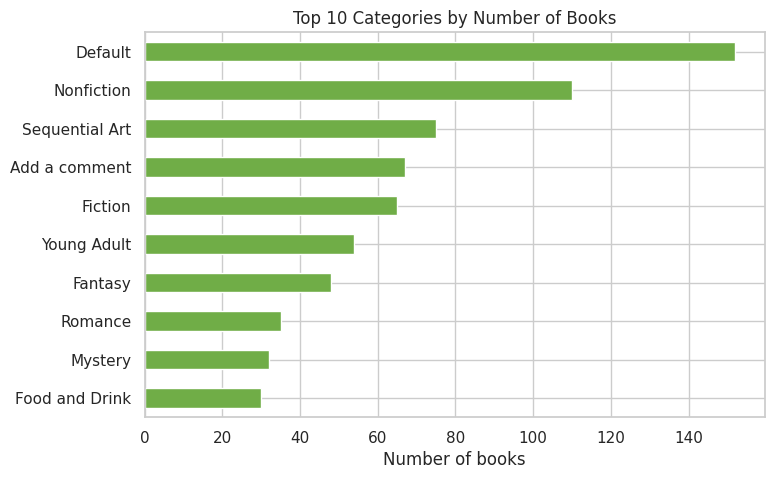

In [23]:
top10 = df["category"].value_counts().head(10)

plt.figure(figsize=(8, 5))
top10.plot(kind="barh", color="#70AD47")
plt.gca().invert_yaxis()
plt.title("Top 10 Categories by Number of Books")
plt.xlabel("Number of books")
plt.ylabel("")
plt.savefig("charts/01_top_categories.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** "Default" (152) and "Nonfiction" (110) are the largest categories. "Default" looks like a catch-all label for books without a genre, so a few broad categories dominate the dataset.

<function matplotlib.pyplot.show(close=None, block=None)>

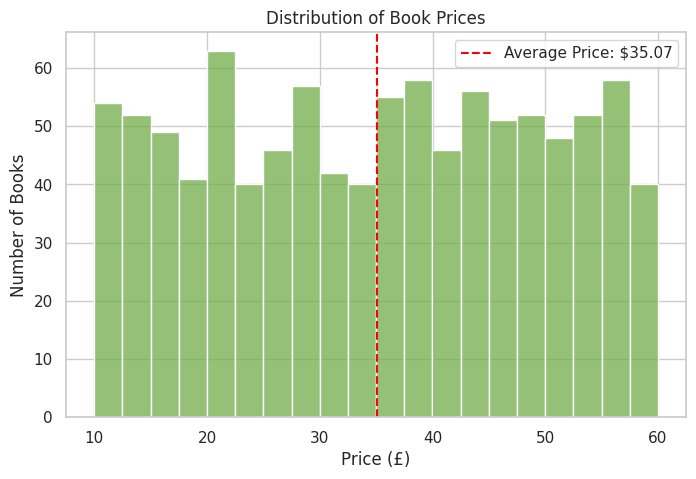

In [24]:
avg_price = df['price'].mean()

plt.figure(figsize=(8, 5))
sns.histplot(df['price'], bins=20, color="#70AD47")
plt.axvline(avg_price, color='red', linestyle='dashed', label=f'Average Price: ${avg_price:.2f}')
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.legend()
plt.savefig("charts/02_price_distribution.png", dpi=150, bbox_inches="tight")
plt.show

**Takeaway:** Prices are spread fairly evenly between £10 and £60, with an average of about £35. No price range dominates, and there is no bell shape, which suggests prices were assigned fairly uniformly.

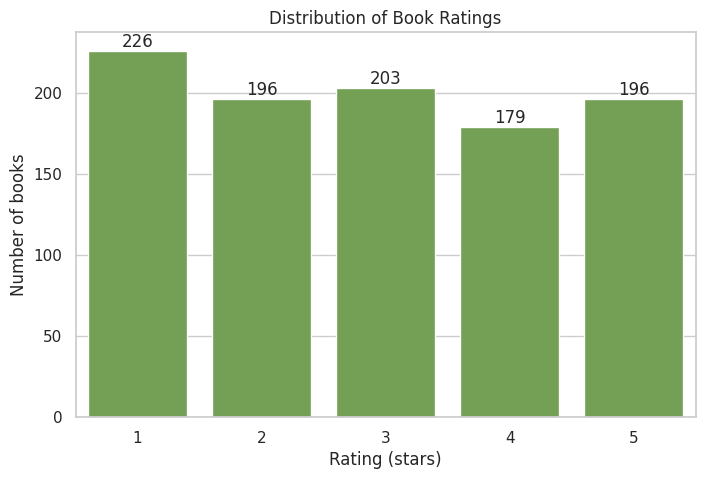

In [25]:
counts = df["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x="rating", y="count", data=counts.reset_index(), color="#70AD47")
plt.title("Distribution of Book Ratings")
plt.xlabel("Rating (stars)")
plt.ylabel("Number of books")

for i, value in enumerate(counts.values):
    plt.text(i, value, str(value), ha="center", va="bottom")

plt.savefig("charts/03_rating_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** Ratings are spread fairly evenly across all five levels, with no single rating dominating, so there is no "typical" rating in this dataset.

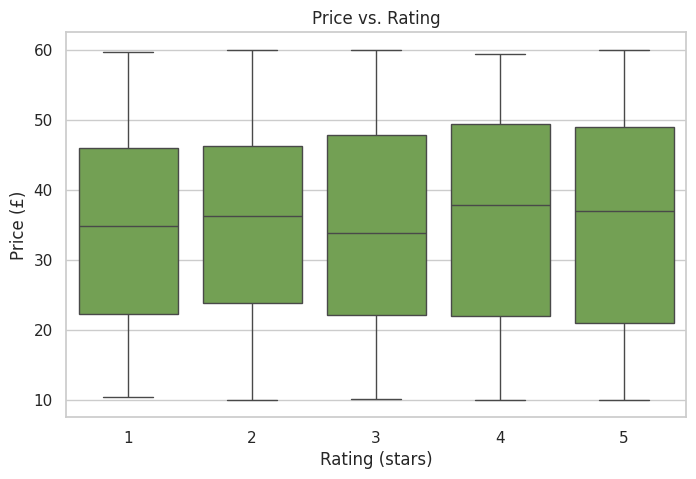

In [26]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="rating", y="price", data=df, color="#70AD47")
plt.title("Price vs. Rating")
plt.xlabel("Rating (stars)")
plt.ylabel("Price (£)")
plt.savefig("charts/04_price_by_rating.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** Price covers roughly the same £10 to £60 range at every rating, and the median price barely changes from 1 to 5 stars. A higher rating does not mean a higher price, which matches the near-zero correlation (r = 0.028) from the EDA.

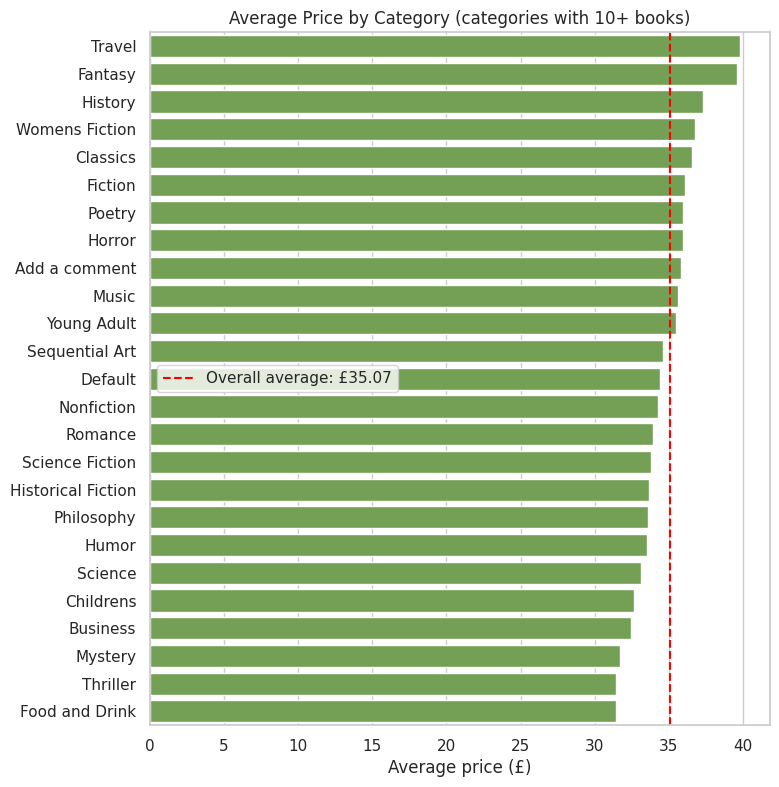

In [27]:
cat_price = df.groupby("category")["price"].agg(["count", "mean"])
cat_price = cat_price[cat_price["count"] >= 10].sort_values("mean", ascending=False)

overall_avg = df["price"].mean()

plt.figure(figsize=(8, 9))
sns.barplot(x="mean", y=cat_price.index, data=cat_price, orient="h", color="#70AD47")
plt.axvline(overall_avg, linestyle="--", color="red", label=f"Overall average: £{overall_avg:.2f}")
plt.title("Average Price by Category (categories with 10+ books)")
plt.xlabel("Average price (£)")
plt.ylabel("")
plt.legend()
plt.savefig("charts/05_price_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** Average price differs by only a few pounds between categories, and all of them sit close to the overall average of about £35. Genre is not a strong signal of price, which matches the ANOVA result from the EDA (p = 0.930).

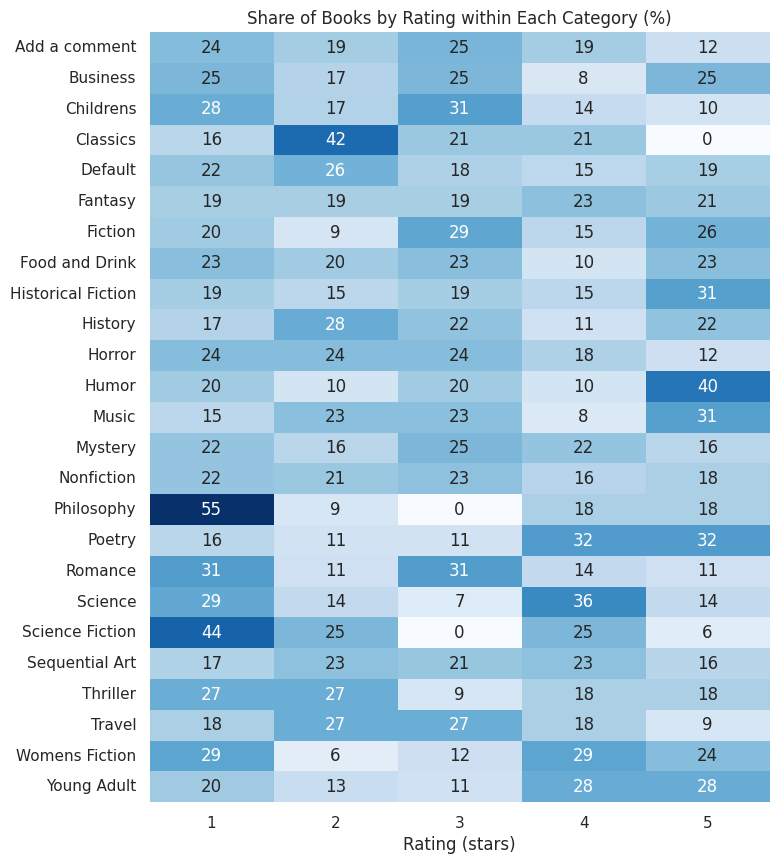

In [28]:
big = df[df["category"].map(df["category"].value_counts()) >= 10]
table = pd.crosstab(big["category"], big["rating"], normalize="index") * 100

plt.figure(figsize=(8, 10))
sns.heatmap(table, annot=True, fmt=".0f", cmap="Blues", cbar=False)
plt.title("Share of Books by Rating within Each Category (%)")
plt.xlabel("Rating (stars)")
plt.ylabel("")
plt.savefig("charts/06_category_rating_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** No category stands out as rated higher or lower than the rest. Ratings are spread across all five levels in every genre, and the bigger swings in small categories reflect small samples, not real differences. This matches the ANOVA result from the EDA (p = 0.390).